Lese inn data

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/zomato_india_clean.csv")
df.head()


,rating,high_rating,cost,log_cost,votes,log_votes,price_range,table_booking,online_delivery,city
0,3.9,1,850,6.745236,140,4.941642,3,0,0,Other
1,3.5,1,700,6.551080,71,4.262680,2,0,0,Other
2,3.6,1,500,6.214608,94,4.543295,2,0,0,Other
3,4.0,1,400,5.991465,87,4.465908,2,0,0,Other
4,4.2,1,1000,6.907755,177,5.176150,3,0,0,Other


Histogram av Vurdering

Laveste rating: 1.8
Høyeste rating: 4.9


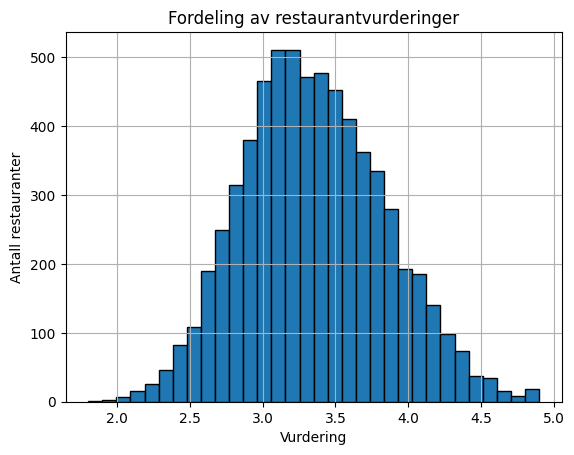

In [25]:
#Finner maks og min rating for å vite antall søyler i histogrammet
print("Laveste rating:", df["rating"].min())
print("Høyeste rating:", df["rating"].max())

df["rating"].dropna().hist(bins=32, edgecolor="black")

plt.xlabel("Vurdering")
plt.ylabel("Antall restauranter")
plt.title("Fordeling av restaurantvurderinger")
plt.show()


Histogram av pris og antall stemmer før og etter log

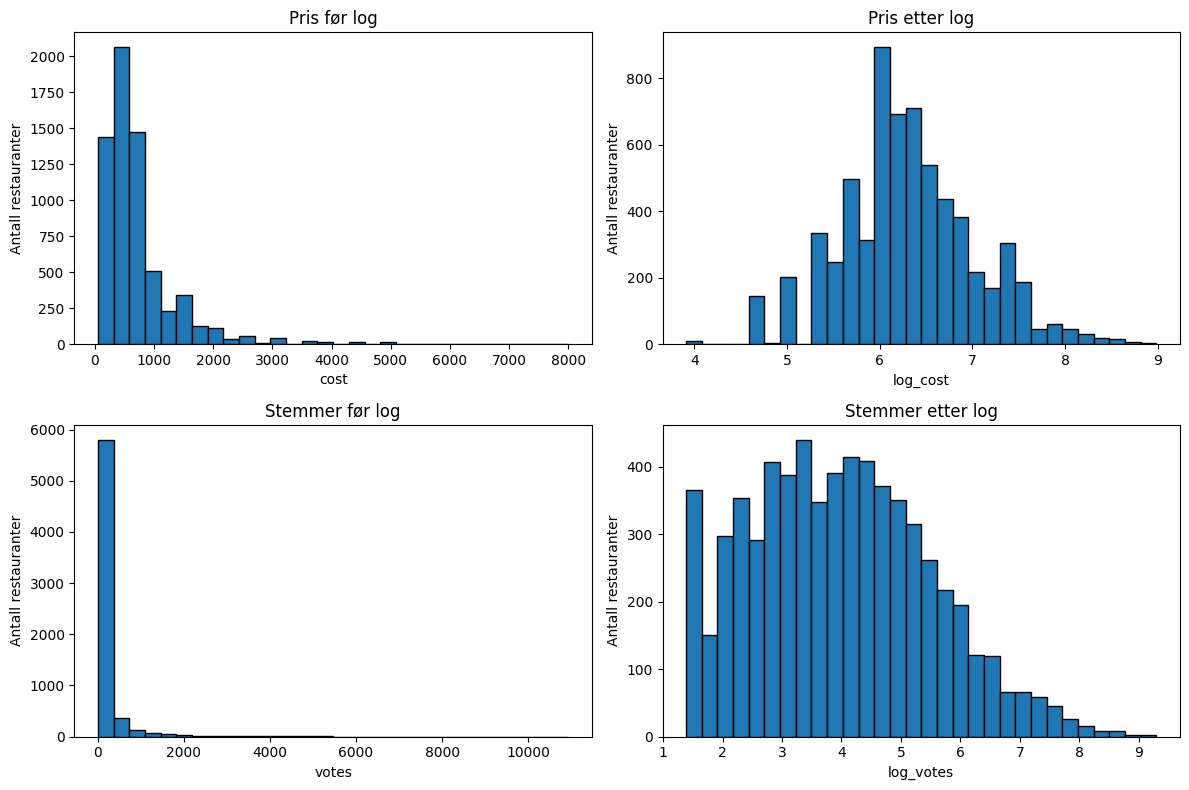

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

kolonner = ["cost", "log_cost", "votes", "log_votes"]
titler = ["Pris før log", "Pris etter log",
          "Stemmer før log", "Stemmer etter log"]

for ax, kolonne, tittel in zip(axes.flat, kolonner, titler):
    ax.hist(df[kolonne].dropna(), bins=30, edgecolor="black")
    ax.set_title(tittel)
    ax.set_xlabel(kolonne)
    ax.set_ylabel("Antall restauranter")

plt.tight_layout()
plt.show()

Spredningsplott av vurdering mot log(pris) og mot log(stemmer)

Text(0.5, 1.0, 'Vurdering mot log(stemmer)')

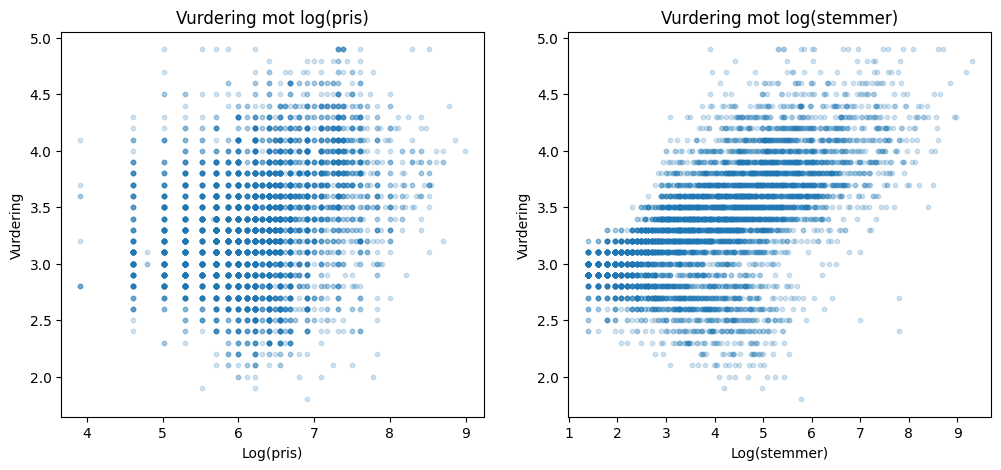

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df["log_cost"], df["rating"], alpha=0.2, s=10)
axes[0].set_xlabel("Log(pris)")
axes[0].set_ylabel("Vurdering")
axes[0].set_title("Vurdering mot log(pris)")

axes[1].scatter(df["log_votes"], df["rating"], alpha=0.2, s=10)
axes[1].set_xlabel("Log(stemmer)")
axes[1].set_ylabel("Vurdering")
axes[1].set_title("Vurdering mot log(stemmer)")

Boksplot for vurdering etter bordebestilling

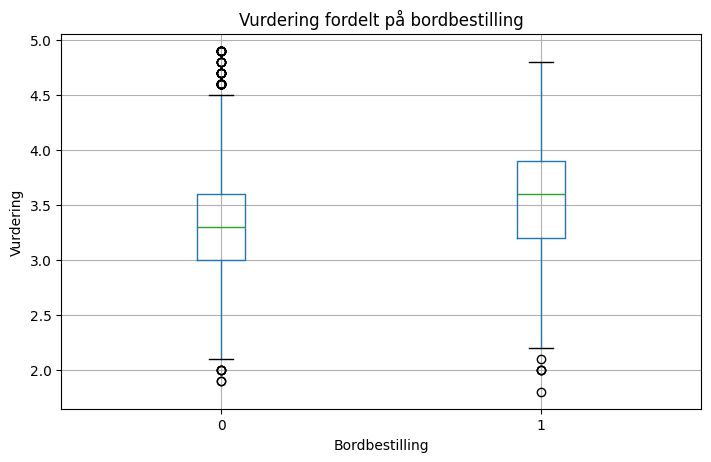

In [47]:
df.boxplot(column="rating", by="table_booking", figsize=(8, 5))
plt.xlabel("Bordbestilling")
plt.ylabel("Vurdering")
plt.suptitle("")
plt.title("Vurdering fordelt på bordbestilling")
plt.show()

Boksplot for vurdering etter by

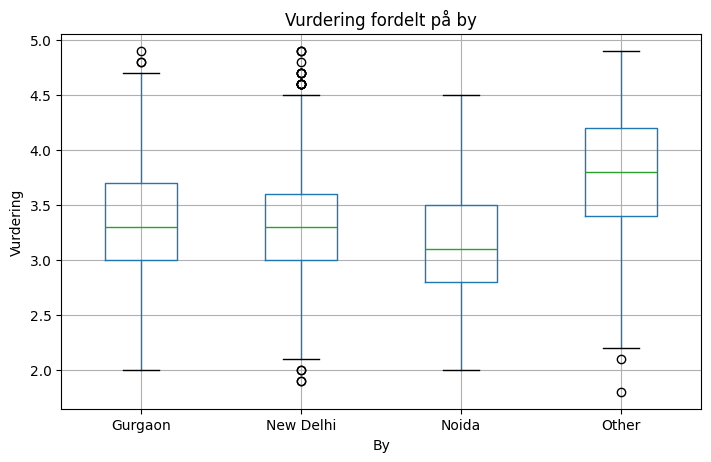

In [48]:
df.boxplot(column="rating", by="city", figsize=(8, 5))
plt.xlabel("By")
plt.ylabel("Vurdering")
plt.suptitle("")
plt.title("Vurdering fordelt på by")
plt.show()

Boksplot for vurdering nettlevering

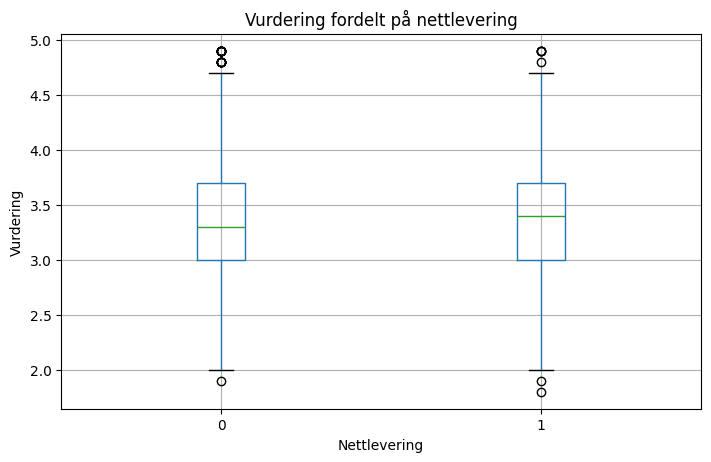

In [49]:
df.boxplot(column="rating", by="online_delivery", figsize=(8, 5))
plt.xlabel("Nettlevering")
plt.ylabel("Vurdering")
plt.suptitle("")
plt.title("Vurdering fordelt på nettlevering")
plt.show()

Korrelasjonsmatrise for alle kategorier utenom byene

In [52]:
kolonner = ["rating", "high_rating", "cost", "log_cost", "votes", "log_votes", "price_range", "table_booking", "online_delivery"]

df[kolonner].corr()

,rating,high_rating,cost,log_cost,votes,log_votes,price_range,table_booking,online_delivery
rating,1.000000,0.808409,0.312530,0.321755,0.397342,0.623422,0.361476,0.174433,0.031343
high_rating,0.808409,1.000000,0.305825,0.321788,0.329375,0.634085,0.350495,0.180191,0.103783
cost,0.312530,0.305825,1.000000,0.860484,0.250576,0.393844,0.826492,0.596040,-0.025179
log_cost,0.321755,0.321788,0.860484,1.000000,0.279805,0.482722,0.893843,0.584933,0.102678
votes,0.397342,0.329375,0.250576,0.279805,1.000000,0.611032,0.283219,0.164084,0.054621
log_votes,0.623422,0.634085,0.393844,0.482722,0.611032,1.000000,0.483383,0.293084,0.223966
price_range,0.361476,0.350495,0.826492,0.893843,0.283219,0.483383,1.000000,0.569961,0.037770
table_booking,0.174433,0.180191,0.596040,0.584933,0.164084,0.293084,0.569961,1.000000,0.038433
online_delivery,0.031343,0.103783,-0.025179,0.102678,0.054621,0.223966,0.037770,0.038433,1.000000
